# Лабораторная работа №1

## Импорт библиотек

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
import time

## Загружаем данные MNIST

In [2]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False)

In [3]:
X = mnist.data
y = mnist.target

X = X.astype('float32')/255.0
y = y.astype('int32')

X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

print("--- Размерности данных ---")
print(f"Всего тренировочных примеров (X_train): {X_train.shape[0]}")
print(f"Всего тестовых примеров (X_test): {X_test.shape[0]}")
print(f"Форма одного изображения (плоский вектор): {X_train.shape[1]}")
print(f"Форма массива меток (y_train): {y_train.shape[0]}")

--- Размерности данных ---
Всего тренировочных примеров (X_train): 60000
Всего тестовых примеров (X_test): 10000
Форма одного изображения (плоский вектор): 784
Форма массива меток (y_train): 60000


## Демонстрация выбранных изображений и меток классов для проверки корректности загрузки

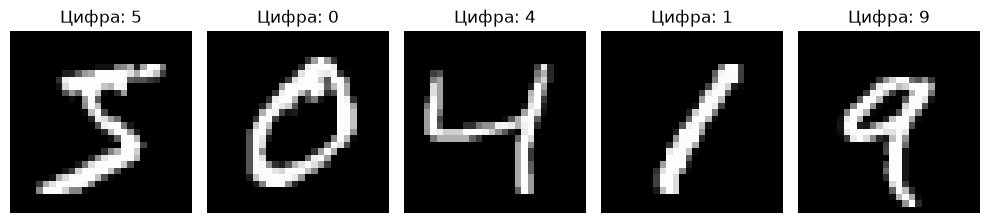

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(10,4))

for i, ax in enumerate(axes.flatten()):
    img = X_train[i].reshape(28, 28)
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Цифра: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Функции активации по заданию

In [5]:
def relu(Z):
    return np.maximum(0, Z)

def derivative_relu(Z):
    return (Z > 0).astype(float)

def softmax(Z):
    exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

## Функция ошибки по заданию - кросс-энтропия

In [6]:
def cross_entropy_loss(predictions, true_labels_one_hot):
    m = true_labels_one_hot.shape[0]
    loss = -np.sum(true_labels_one_hot * np.log(predictions + 1e-9)) / m
    return loss

## Параметры сети

In [7]:
input_size = 784 # 28 x 28
hidden_size = 300
output_size = 10

In [8]:
np.random.seed(42)

## Веса и сдвиги первого слоя

In [9]:
W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
b1 = np.zeros((1, hidden_size))

## Веса и сдвиги второго слоя

In [10]:
W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
b2 = np.zeros((1, output_size))

## Проверка правильности струкутры

In [11]:
print(f"Форма W1: {W1.shape}")
print(f"Форма b1: {b1.shape}")
print(f"Форма W2: {W2.shape}")
print(f"Форма b2: {b2.shape}")

Форма W1: (784, 300)
Форма b1: (1, 300)
Форма W2: (300, 10)
Форма b2: (1, 10)


## One-Hot кодирование меток

In [12]:
def one_hot_encode(y, classes_numbers=10):
    one_hot = np.zeros((y.shape[0], classes_numbers))
    one_hot[np.arange(y.shape[0]), y] = 1
    return one_hot

## Прямой проход

In [13]:
def forward_pass(X, W1, b1, W2, b2):
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)
    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)
    saved_values = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, saved_values

## Обратный проход

In [14]:
def backward_pass(X, y_one_hot, saved_values, W1, W2):
    Z1, A1, Z2, A2 = saved_values["Z1"], saved_values["A1"], saved_values["Z2"], saved_values["A2"]
    m = X.shape[0]
    
    d_Z2 = A2 - y_one_hot
    d_W2 = np.dot(A1.T, d_Z2) / m
    d_b2 = np.sum(d_Z2, axis=0, keepdims=True) / m
    
    d_A1 = np.dot(d_Z2, W2.T)
    d_Z1 = d_A1 * derivative_relu(Z1)
    d_W1 = np.dot(X.T, d_Z1) / m
    d_b1 = np.sum(d_Z1, axis=0, keepdims=True) / m
    
    gradients = {"d_W1": d_W1, "d_b1": d_b1, "d_W2": d_W2, "d_b2": d_b2}
    return gradients

## Обновление весов

In [15]:
def update_weights(W1, b1, W2, b2, gradients, learning_rate):
    W1 = W1 - learning_rate * gradients["d_W1"]
    b1 = b1 - learning_rate * gradients["d_b1"]
    W2 = W2 - learning_rate * gradients["d_W2"]
    b2 = b2 - learning_rate * gradients["d_b2"]
    return W1, b1, W2, b2

## Гиперпараметры

In [16]:
learning_rate = 0.1
batch_size = 32 
epochs = 20

## Обучение нейронной сети

In [17]:
y_train_one_hot = one_hot_encode(y_train)

loss_history = []
accuracy_history = []

print("Начинаем обучение нейронной сети")
print("=" * 70)

for epoch in range(epochs):
    start_time = time.time()
    
    indices = np.arange(X_train.shape[0])
    np.random.shuffle(indices)
    X_shuffled = X_train[indices]
    y_shuffled_one_hot = y_train_one_hot[indices]
    y_shuffled_labels = y_train[indices]
    
    epoch_loss = 0.0
    epoch_correct = 0
    num_batches = 0
    
    for i in range(0, X_train.shape[0], batch_size):
        X_batch = X_shuffled[i:i+batch_size]
        y_batch_targets = y_shuffled_one_hot[i:i+batch_size]
        y_batch_labels = y_shuffled_labels[i:i+batch_size]
        
        predictions, saved_values = forward_pass(X_batch, W1, b1, W2, b2)
        batch_loss = cross_entropy_loss(predictions, y_batch_targets)
        epoch_loss += batch_loss
        
        predicted_labels = np.argmax(predictions, axis=1)
        epoch_correct += np.sum(predicted_labels == y_batch_labels)
        
        gradients = backward_pass(X_batch, y_batch_targets, saved_values, W1, W2)
        
        W1, b1, W2, b2 = update_weights(W1, b1, W2, b2, gradients, learning_rate)
        num_batches += 1
    
    avg_loss = epoch_loss / num_batches
    train_accuracy = epoch_correct / X_train.shape[0]
    classification_error = 1 - train_accuracy
    
    epoch_time = time.time() - start_time
    
    loss_history.append(avg_loss)
    accuracy_history.append(train_accuracy * 100)
    
    print(f"Эпоха {epoch+1:2d}/{epochs} | "
         f"Loss: {avg_loss:.4f} | "
         f"Ошибка: {classification_error:.4f} | "
         f"Точность: {train_accuracy*100:.4f} | "
         f"Время: {epoch_time:.2f} с"
         )

print("=" * 70)
print(f"Обучение завершено. Финальная точность на train: {accuracy_history[-1]:.2f}")

Начинаем обучение нейронной сети
Эпоха  1/20 | Loss: 0.2870 | Ошибка: 0.0818 | Точность: 91.8183 | Время: 10.47 с
Эпоха  2/20 | Loss: 0.1324 | Ошибка: 0.0385 | Точность: 96.1533 | Время: 11.03 с
Эпоха  3/20 | Loss: 0.0941 | Ошибка: 0.0273 | Точность: 97.2683 | Время: 11.74 с
Эпоха  4/20 | Loss: 0.0719 | Ошибка: 0.0208 | Точность: 97.9233 | Время: 11.34 с
Эпоха  5/20 | Loss: 0.0577 | Ошибка: 0.0164 | Точность: 98.3550 | Время: 11.01 с
Эпоха  6/20 | Loss: 0.0476 | Ошибка: 0.0129 | Точность: 98.7133 | Время: 11.19 с
Эпоха  7/20 | Loss: 0.0399 | Ошибка: 0.0107 | Точность: 98.9300 | Время: 12.35 с
Эпоха  8/20 | Loss: 0.0330 | Ошибка: 0.0087 | Точность: 99.1333 | Время: 11.87 с
Эпоха  9/20 | Loss: 0.0279 | Ошибка: 0.0072 | Точность: 99.2817 | Время: 11.07 с
Эпоха 10/20 | Loss: 0.0235 | Ошибка: 0.0053 | Точность: 99.4667 | Время: 11.24 с
Эпоха 11/20 | Loss: 0.0194 | Ошибка: 0.0037 | Точность: 99.6267 | Время: 11.18 с
Эпоха 12/20 | Loss: 0.0169 | Ошибка: 0.0031 | Точность: 99.6850 | Время: 11.

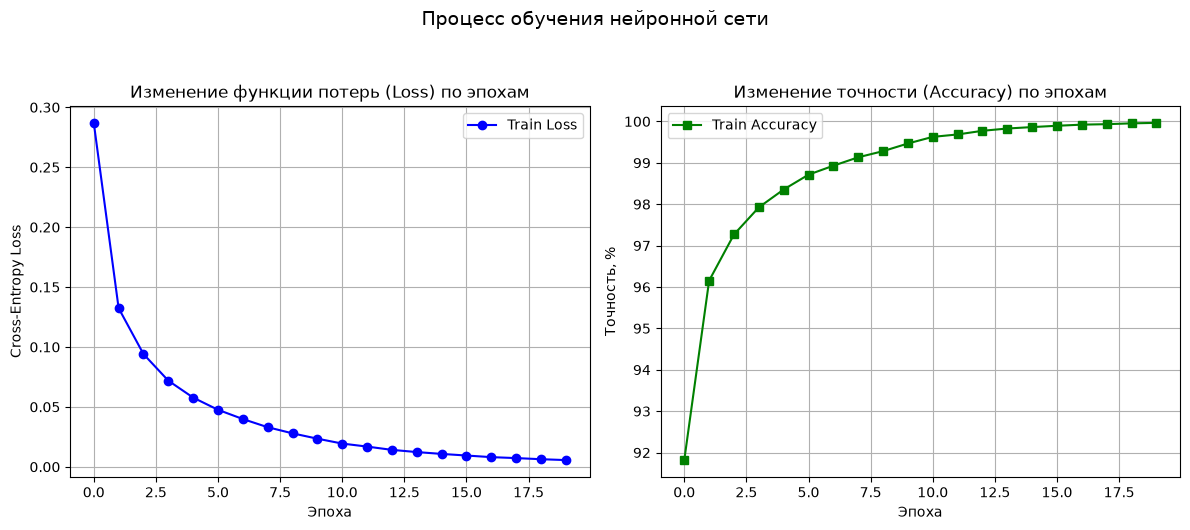

In [18]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(loss_history, label='Train Loss', color='blue', marker='o')
plt.title('Изменение функции потерь (Loss) по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(accuracy_history, label='Train Accuracy', color='green', marker='s')
plt.title('Изменение точности (Accuracy) по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Точность, %')
plt.grid(True)
plt.legend()

plt.suptitle('Процесс обучения нейронной сети', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [19]:
y_test_one_hot = one_hot_encode(y_test)

test_predictions, _ = forward_pass(X_test, W1, b1, W2, b2)

test_predicted_labels = np.argmax(test_predictions, axis=1)

test_accuracy = np.mean(test_predicted_labels == y_test)
test_classification_error = 1 - test_accuracy
test_loss = cross_entropy_loss(test_predictions, y_test_one_hot)

print("=" * 70)
print("Результаты на тестовой выборке:")
print(f"Cross-Entropy Loss: {test_loss:.4f}")
print(f"Ошибка классификации: {test_classification_error:.4f}")
print(f"Точность (Accuracy): {test_accuracy*100:.2f}%")
print("=" * 70)

if test_accuracy > 0.95:
    print("Требование задания выполнено: точность на тесте > 95%")
else:
    print("Внимание: точность на тесте < 95%")

Результаты на тестовой выборке:
Cross-Entropy Loss: 0.0614
Ошибка классификации: 0.0182
Точность (Accuracy): 98.18%
Требование задания выполнено: точность на тесте > 95%


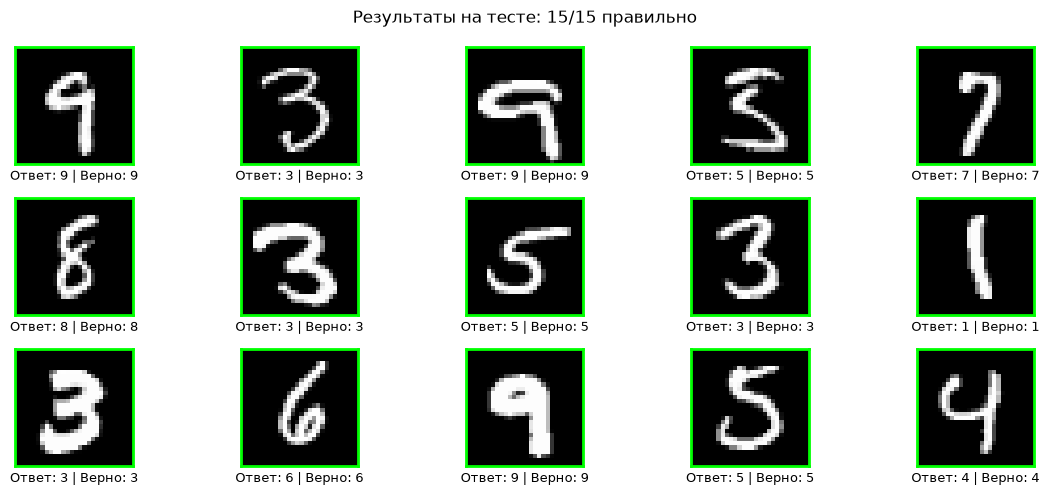

In [20]:
num_examples = 15

random_idx = np.random.choice(len(X_test), num_examples, replace=False)
sample_images = X_test[random_idx]
sample_labels = y_test[random_idx]

sample_predictions, _ = forward_pass(sample_images, W1, b1, W2, b2)
predicted_classes = np.argmax(sample_predictions, axis=1)

correct_predictions = np.sum(predicted_classes == sample_labels)

fig, axes = plt.subplots(3, 5, figsize=(12, 5))
axes = axes.flatten()

for idx, ax in enumerate(axes):
    ax.imshow(sample_images[idx].reshape(28, 28), cmap='gray')

    is_right = (predicted_classes[idx] == sample_labels[idx])

    border_color = 'lime' if is_right else 'red'
    for spine in ax.spines.values():
        spine.set_edgecolor(border_color)
        spine.set_linewidth(2)

    ax.set_xlabel(f'Ответ: {predicted_classes[idx]} | Верно: {sample_labels[idx]}', 
                  fontsize = 9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(f'Результаты на тесте: {correct_predictions}/{num_examples} правильно')
plt.subplots_adjust(hspace=0.6, wspace=0.3)
plt.tight_layout()
plt.show()